# 3. QCNN v3: 16 qubits y lectura ⟨Z⟩ con capa lineal

v3 sustituye la lectura por probabilidades por los valores esperados ⟨Z⟩ de los 4 qubits finales, seguidos de una capa lineal 4 → 10 entrenable. Al mismo tiempo escala el modelo: imagen de 16×16, parches de 4×4 y un qubit por cada uno de los 16 parches, con una pirámide completa 16 → 8 → 4. Al final, una ablación separa los dos cambios: el circuito de v2 con la lectura de v3.

El protocolo (datos, optimizador, semillas, métrica) es el del notebook 01. Con cabeza lineal, la pérdida es la entropía cruzada sobre los 10 logits, sin término de *ghost states*.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from qcnn_mnist import figuras
from qcnn_mnist import resultados as res

figuras.aplicar_estilo()
R = res.cargar()   # modelo -> resultados por semilla (results/<modelo>/semilla_<s>.json)
S = res.resumen(R) # modelo -> media y desviación entre semillas

## Datos a 16×16

Con parches de 4×4, la imagen de 16×16 forma una rejilla de 4×4 parches, y v3 los usa todos.

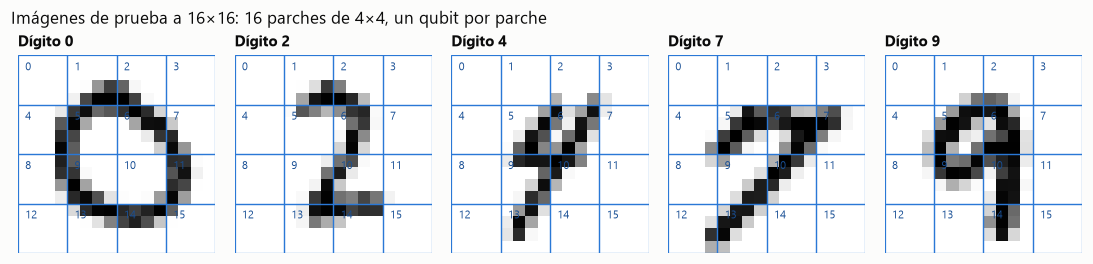

In [2]:
from qcnn_mnist.datos import preparar_datos

datos16 = preparar_datos(16)
indices = [int(np.flatnonzero(datos16.y_test == c)[0]) for c in (0, 2, 4, 7, 9)]

fig, ejes = plt.subplots(1, len(indices), figsize=(10, 2.4))
for ax, i in zip(ejes, indices):
    figuras.rejilla_parches(ax, datos16.x_test[i], 4, titulo=f"Dígito {datos16.y_test[i]}")
fig.suptitle("Imágenes de prueba a 16×16: 16 parches de 4×4, un qubit por parche", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
figuras.guardar(fig, "03_parches_16x16")
plt.show()

## Circuito de v3

1. **Codificación:** $R_Y(\theta)$ por parche, con la misma capa de entrada que v2 (aquí $W$ es 2×16).
2. **Convolución** $\mathrm{Rot}$ + anillo de CNOT sobre los 16 qubits.
3. **Pooling paramétrico** 16 → 8: en cada par, una CNOT del qubit descartado al superviviente y una $R_Y$ entrenable en el superviviente.
4. ***Re-uploading*** en los 8 supervivientes.
5. **Convolución** sobre 8, **pooling** 8 → 4 y **convolución** sobre 4.
6. **Lectura:** ⟨Z⟩ de los 4 qubits finales y capa lineal 4 → 10 con bias.

| Bloque | Parámetros |
| --- | ---: |
| Capa de entrada ($W$ 2×16, $b$) | 34 |
| Circuito (convoluciones 48 + 24 + 12, pooling 8 + 4) | 96 |
| Capa de salida (4 × 10 + 10) | 50 |
| **Total** | **180** |

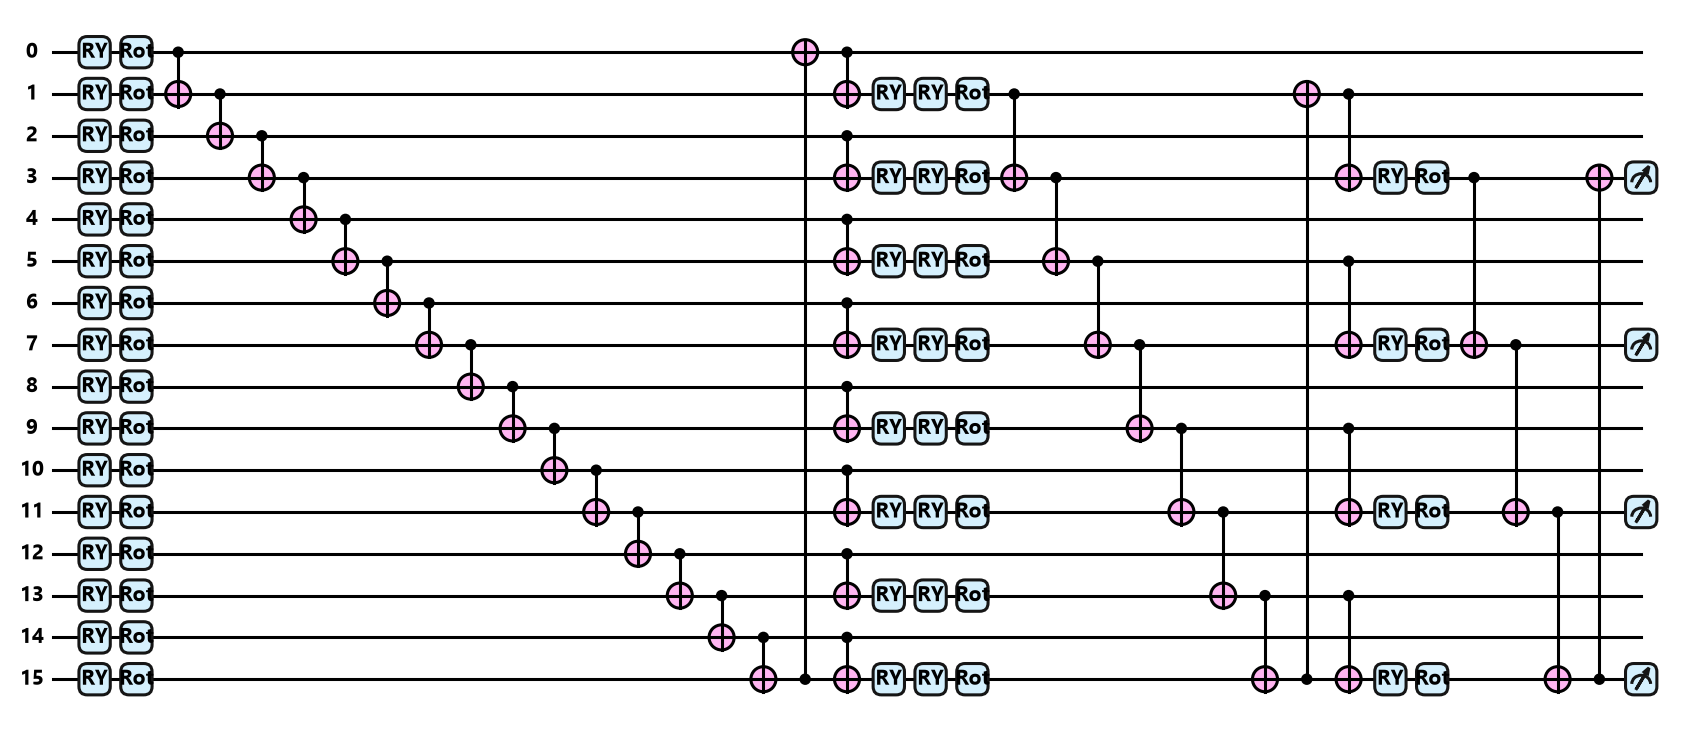

Parámetros entrenables de v3: 180


In [3]:
fig = figuras.circuito("qcnn_v3", escala=0.38)
figuras.guardar(fig, "03_circuito_v3")
plt.show()
print(f"Parámetros entrenables de v3: {S['qcnn_v3'].n_parametros}")

## Resultados

Los controles de esta resolución ven los mismos 16 parches:

- **CNN 16×16:** un filtro de 4×4 con paso 4, una capa densa de 16 unidades y la salida.
- **CPN 16×16:** la pirámide clásica 16 → 8 → 4 con tres capas $\tanh$, espejo de las tres convoluciones de v3, y la misma salida lineal 4 → 10. Es la comparación más directa: los dos modelos comprimen la imagen a **4 valores** antes de la capa lineal.

In [4]:
display(Markdown(res.tabla_markdown(S, ["qcnn_v2", "qcnn_v3", "cpn_16", "cnn_16"])))

| Modelo | Parámetros | Accuracy de prueba (%) | Accuracy de entrenamiento (%) | Cómputo (h) |
| --- | ---: | ---: | ---: | ---: |
| QCNN v2 | 64 | 23,1 ± 4,6 | 22,2 ± 4,3 | 0,07 |
| QCNN v3 | 180 | 43,3 ± 3,0 | 45,7 ± 1,9 | 5,43 |
| CPN 16×16 | 112 | 61,0 ± 5,0 | 60,4 ± 5,9 | 0,01 |
| CNN 16×16 | 459 | 77,1 ± 1,6 | 83,0 ± 1,7 | 0,01 |

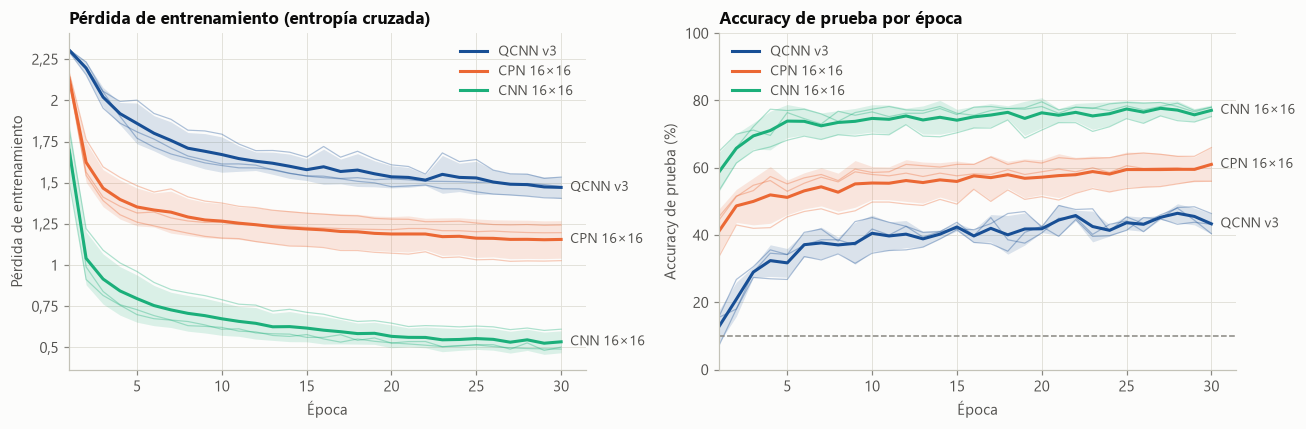

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
figuras.curvas(ax1, R, ["qcnn_v3", "cpn_16", "cnn_16"], "perdida_train")
ax1.set_title("Pérdida de entrenamiento (entropía cruzada)")
figuras.curvas(ax2, R, ["qcnn_v3", "cpn_16", "cnn_16"], "acc_test_por_epoca")
ax2.axhline(100 * figuras.AZAR, color=figuras.TINTA_TENUE, linestyle="--", linewidth=1)
ax2.set_ylim(0, 100)
ax2.set_title("Accuracy de prueba por época")
fig.tight_layout()
figuras.guardar(fig, "03_curvas_v3")
plt.show()

Pérdida media de v3: época 20 1,536, época 30 1,471
Accuracy de entrenamiento 45,7 % frente a prueba 43,3 %


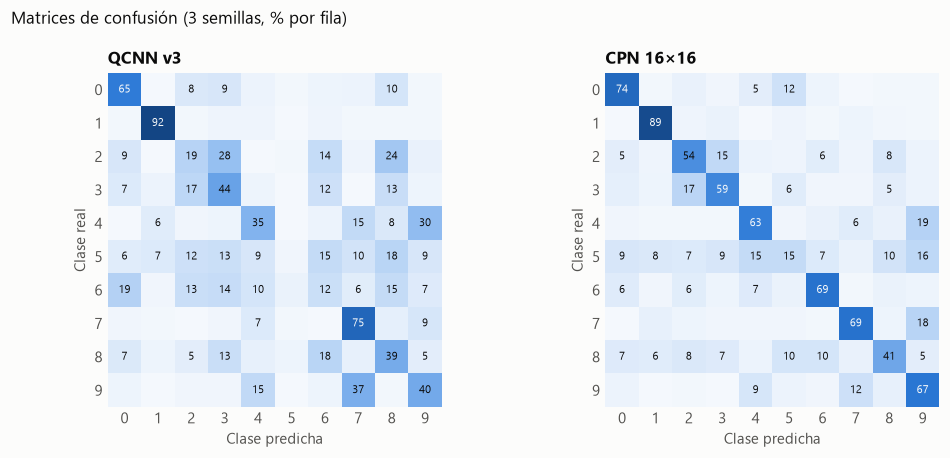

In [6]:
v3 = R["qcnn_v3"]
perdida = res.serie(v3, "perdida_train").mean(0)
print(f"Pérdida media de v3: época 20 {res.num(perdida[19], 3)}, época 30 {res.num(perdida[29], 3)}")
print(f"Accuracy de entrenamiento {res.pct(S['qcnn_v3'].acc_train_media)} % frente a prueba {res.pct(S['qcnn_v3'].acc_test_media)} %")

fig, ejes = plt.subplots(1, 2, figsize=(9.2, 4.2))
figuras.confusion(ejes[0], v3, "QCNN v3")
figuras.confusion(ejes[1], R["cpn_16"], "CPN 16×16")
fig.suptitle("Matrices de confusión (3 semillas, % por fila)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
figuras.guardar(fig, "03_confusion_v3_cpn16")
plt.show()

## ¿Cuánto de la mejora se debe a la lectura?

v3 cambia varias cosas a la vez respecto de v2: la lectura, la resolución, el número de parches y de qubits, y el pooling. Para separarlas se entrena una ablación, **v2 con lectura ⟨Z⟩**: el circuito de v2 sin ningún cambio (10×10, 10 qubits de la banda central, $\mathrm{Rot}$, *re-uploading*, pooling fijo, bias de entrada entrenable) medido con ⟨Z⟩ de sus 4 qubits finales y seguido de una capa lineal 4 → 10 con bias. La pérdida es la entropía cruzada, sin penalización de estados sobrantes. Tiene 64 parámetros de v2 más 50 de la capa de salida.

Con ella, el paso de v2 a v3 se parte en dos: primero cambia solo la lectura; después, solo la escala. Los controles clásicos, que no cambian de lectura entre 10×10 y 16×16, indican cuánto puede aportar la escala a un modelo que la aprovecha.

In [7]:
display(Markdown(res.tabla_markdown(S, [*res.EVOLUCION[1:], "cpn_10", "cpn_16"])))
display(Markdown(res.tabla_ganancias(S, res.PASOS_V2_V3)))

| Modelo | Parámetros | Accuracy de prueba (%) | Accuracy de entrenamiento (%) | Cómputo (h) |
| --- | ---: | ---: | ---: | ---: |
| QCNN v2 | 64 | 23,1 ± 4,6 | 22,2 ± 4,3 | 0,07 |
| v2 con lectura ⟨Z⟩ | 114 | 44,7 ± 2,3 | 45,7 ± 2,9 | 0,09 |
| QCNN v3 | 180 | 43,3 ± 3,0 | 45,7 ± 1,9 | 5,43 |
| CPN 10×10 | 78 | 46,9 ± 0,8 | 46,9 ± 1,3 | 0,01 |
| CPN 16×16 | 112 | 61,0 ± 5,0 | 60,4 ± 5,9 | 0,01 |

| Paso | Ganancia (puntos) | Qué cambia |
| --- | ---: | --- |
| QCNN v2 → v2 con lectura ⟨Z⟩ | +21,6 | solo la lectura (⟨Z⟩ + capa lineal) |
| v2 con lectura ⟨Z⟩ → QCNN v3 | -1,3 | resolución, parches, qubits y pooling |
| QCNN v2 → QCNN v3 | +20,3 | las dos cosas |
| CPN 10×10 → CPN 16×16 | +14,1 | resolución y parches |
| CNN 10×10 → CNN 16×16 | +17,2 | resolución y parches |

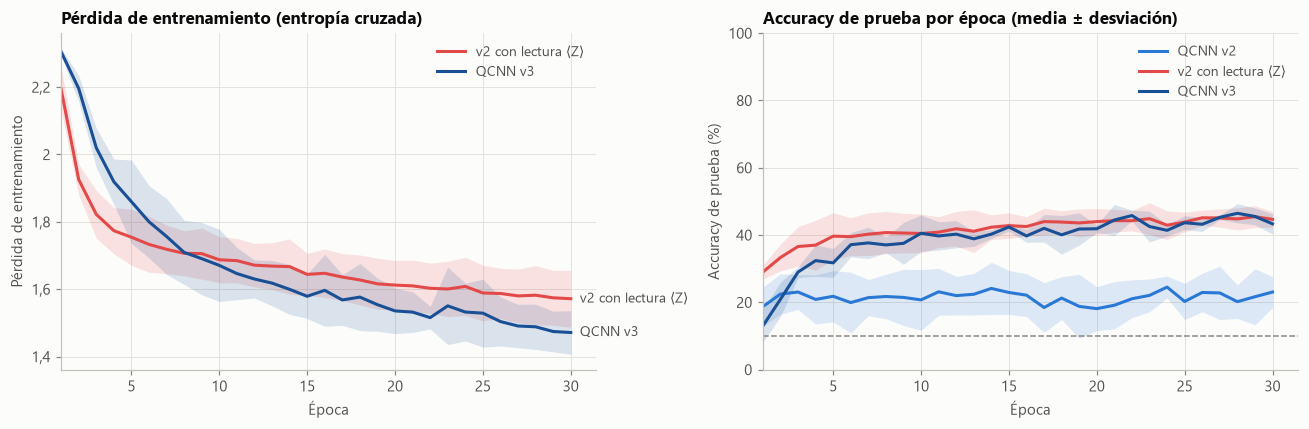

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
figuras.curvas(ax1, R, ["v2_lectura_z", "qcnn_v3"], "perdida_train", semillas=False)
ax1.set_title("Pérdida de entrenamiento (entropía cruzada)")
figuras.curvas(ax2, R, res.EVOLUCION[1:], "acc_test_por_epoca", semillas=False, etiquetas=False)
ax2.axhline(100 * figuras.AZAR, color=figuras.TINTA_TENUE, linestyle="--", linewidth=1)
ax2.set_ylim(0, 100)
ax2.set_title("Accuracy de prueba por época (media ± desviación)")
fig.tight_layout()
figuras.guardar(fig, "03_ablacion_lectura")
plt.show()

- **La lectura explica la mejora.** Con el mismo circuito, cambiar solo la lectura lleva a v2 al nivel de v3 y cerca de la CPN 10×10, que ve los mismos parches; las curvas de las dos versiones con lectura ⟨Z⟩ casi se superponen.
- **La escala no añade accuracy medible a la QCNN.** El paso de v2 con lectura ⟨Z⟩ a v3 queda dentro de la variación entre semillas, mientras que los controles clásicos ganan con claridad al pasar a 16×16 con todos los parches. El circuito de 16 qubits ve toda la imagen, pero no convierte esa información adicional en accuracy, al menos con esta pirámide y este entrenamiento.

## Coste de cómputo

In [9]:
for m in ["qcnn_v1", "qcnn_v2", "v2_lectura_z", "qcnn_v3", "cpn_16", "cnn_16"]:
    print(f"{res.NOMBRES[m]:<20} {res.num(S[m].horas, 2):>6} h para 3 semillas ({res.num(S[m].horas * 60 / 3):>6} min por semilla)")

QCNN v1                0,06 h para 3 semillas (   1,3 min por semilla)
QCNN v2                0,07 h para 3 semillas (   1,5 min por semilla)
v2 con lectura ⟨Z⟩     0,09 h para 3 semillas (   1,9 min por semilla)
QCNN v3                5,43 h para 3 semillas ( 108,5 min por semilla)
CPN 16×16              0,01 h para 3 semillas (   0,1 min por semilla)
CNN 16×16              0,01 h para 3 semillas (   0,1 min por semilla)


Simular 16 qubits cuesta varias horas por modelo en la CPU de un portátil, frente a minutos para 10 qubits y segundos para los controles clásicos. Es el coste de simular el circuito, no de ejecutarlo en hardware cuántico, pero condiciona cuántas configuraciones se pueden explorar. Aquí, además, ese coste no compra accuracy: v2 con lectura ⟨Z⟩ llega al mismo resultado.

## Lectura

- **Con lectura ⟨Z⟩ + lineal la QCNN aprende de forma consistente.** Tanto v3 como v2 con esa lectura bajan la pérdida de forma sostenida, terminan en valores parecidos entre semillas y quedan muy por encima de v1 y v2. La lectura por probabilidades era el cuello de botella de las dos primeras versiones.
- **Escalar a 16 qubits no mejora el resultado.** v3 queda al nivel de v2 con lectura ⟨Z⟩, aunque ve toda la imagen.
- **No hay sobreajuste.** La accuracy de entrenamiento y la de prueba están cerca; la pérdida todavía baja al final, así que más épocas podrían mejorar algo el resultado.
- **La CPN 16×16 la supera.** Con la misma compresión a 4 valores y menos parámetros, el control clásico obtiene más accuracy, y la CNN, que no comprime a 4 valores, aún más. Algunas clases (el 5, sobre todo) casi nunca se predicen en v3.
- Ver la pirámide completa del circuito como una caja negra no dice qué parte del resultado se debe al circuito. El notebook 04 lo mide con ablaciones.